### An Optimal DL Approach to Breast Cancer Tissue Detection using Case Studies

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
#for dirname, _, filenames in os.walk('/kaggle/input'):
#    for filename in filenames:
#        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [3]:
#### import tensorflow_addons as tfa
from tqdm import tqdm


import tensorflow as tf
print(tf.__version__)
print(tf.test.gpu_device_name())

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
#config.gpu_options.per_process_gpu_memory_fraction = 0.9
#tf.compat.v1.keras.backend.set_session(tf.compat.v1.Session(config=config))

2.6.4
/device:GPU:0


In [4]:
!pip install imutils

  Preparing metadata (setup.py) ... done
  Created wheel for imutils: filename=imutils-0.5.4-py3-none-any.whl size=25858 sha256=fbe299d50007773689420040d8538d62f4a40a8a4d2e56c9bbbe8be068fd823a
  Stored in directory: /root/.cache/pip/wheels/86/d7/0a/4923351ed1cec5d5e24c1eaf8905567b02a0343b24aa873df2
Successfully built imutils


In [5]:
# set the matplotlib backend so figures can be saved in the background
import matplotlib
#matplotlib.use("Agg")
%matplotlib inline

# import the necessary packages
from tensorflow import keras
from keras.preprocessing import image
from keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from keras.callbacks import LearningRateScheduler
#from keras.optimizers import Adagrad, Adam
from keras.utils import np_utils
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
#from pyimagesearch.cancernet import CancerNet
#from pyimagesearch import config
from imutils import paths
import matplotlib.pyplot as plt
import numpy as np
import argparse
import os
import seaborn as sns

In [6]:
BASE_PATH = '../input/idc-dataset/IDC'
print(os.listdir(BASE_PATH))

['validation', 'training', 'testing']


## Global Parameters

In [30]:
#configure BATCH_SIZE BS 
NUM_EPOCHS = 5
INIT_LR = 1e-2
BS = 32
NUM_CLASSES = 2
W, H, C = 48, 48, 3

input_shape=(48, 48, 3)
num_classes=2
weight_decay = 0.0001
learning_rate = 0.001
label_smoothing = 0.1
validation_split = 0.2
batch_size = 4  # thes best one till now is 4
num_epochs = 50
# patch_size = 2
# num_patches = (input_shape[0] // patch_size) ** 2
# embedding_dim = 64
# mlp_dim = 64
# dim_coefficient = 4
# num_heads = 4
# attention_dropout = 0.2
# projection_dropout = 0.2
# num_transformer_blocks = 8  # Number of repetitions of the transformer layer


patch_size = 16
num_patches = (input_shape[0] // patch_size) * (input_shape[1] // patch_size)
embedding_dim = 128
num_heads = 4
mlp_dim = 256
num_transformer_blocks = 4
attention_dropout = 0.1
projection_dropout = 0.1
# learning_rate = 1e-4
# weight_decay = 1e-4
# label_smoothing = 0.1
print(f"Patch size: {patch_size} X {patch_size} = {patch_size ** 2} ")
print(f"Patches per image: {num_patches}")
output_folder=f"breakhis_results/epochs_{num_epochs}_batch_{batch_size}_patch_{patch_size}"
output_dir = os.makedirs(output_folder, exist_ok=True)

Patch size: 16 X 16 = 256 
Patches per image: 9


In [8]:
# derive the training, validation, and testing directories
TRAIN_PATH = os.path.sep.join([BASE_PATH, "training"])
VAL_PATH = os.path.sep.join([BASE_PATH, "validation"])
#VAL_PATH = os.path.sep.join([BASE_PATH, "validating"]) #example 
TEST_PATH = os.path.sep.join([BASE_PATH, "testing"])

# define the amount of data that will be used training
TRAIN_SPLIT = 0.8

# the amount of validation data will be a percentage of the
# *training* data
VAL_SPLIT = 0.1

In [9]:
trainPaths = list(paths.list_images(TRAIN_PATH))   
totalTrain = len(trainPaths)
print(totalTrain)

199818


In [10]:
testPaths = list(paths.list_images(TEST_PATH))
totalTest = len(testPaths)
totalTest

55505

In [11]:
valPaths = list(paths.list_images(VAL_PATH))
totalVal = len(list(paths.list_images(VAL_PATH)))
totalVal

22201

In [12]:
totalTrain, totalVal, totalTest

(199818, 22201, 55505)

In [13]:
# account for skew in the labeled data
trainLabels = [int(p.split(os.path.sep)[-2]) for p in trainPaths]
trainLabels = np_utils.to_categorical(trainLabels)

classTotals = trainLabels.sum(axis=0)
classWeight = classTotals.max() / classTotals

trainLabels.shape, trainLabels[:3], classTotals, classWeight

((199818, 2),
 array([[1., 0.],
        [1., 0.],
        [1., 0.]], dtype=float32),
 array([143056.,  56762.], dtype=float32),
 array([1.       , 2.5202777], dtype=float32))

/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


[0 1] [143056  56762] 199818


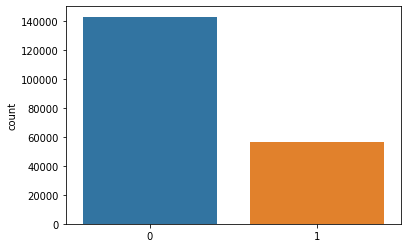

In [14]:
trainCounts = [int(p.split(os.path.sep)[-2]) for p in trainPaths]
sns.countplot(trainCounts)
u, c = np.unique(trainCounts, return_counts=True)
print(u, c, np.sum(c))

[0 1] [39793 15712] 55505


/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


array([[1., 0.],
       [1., 0.],
       [1., 0.]], dtype=float32)

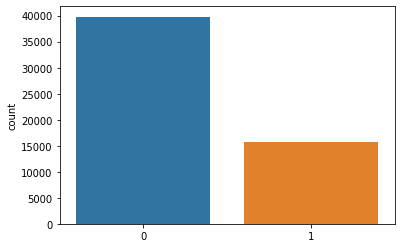

In [15]:
testLabels = [int(p.split(os.path.sep)[-2]) for p in testPaths]
sns.countplot(testLabels)
u, c = np.unique(testLabels, return_counts=True)
print(u, c, np.sum(c))

testLabels = np_utils.to_categorical(testLabels)
testLabels[0:3]

[0 1] [15889  6312] 22201


/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


array([[1., 0.],
       [1., 0.],
       [1., 0.]], dtype=float32)

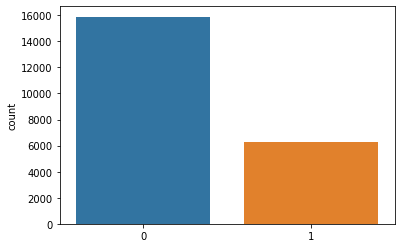

In [16]:
valLabels = [int(p.split(os.path.sep)[-2]) for p in valPaths]
sns.countplot(valLabels)
u, c = np.unique(valLabels, return_counts=True)
print(u, c, np.sum(c))

valLabels = np_utils.to_categorical(valLabels)
valLabels[0:3]

In [17]:
Y_train = trainLabels
Y_val = valLabels
Y_test = testLabels

Y_train.shape, Y_val.shape, Y_test.shape

((199818, 2), (22201, 2), (55505, 2))

In [18]:
# initialize the training training data augmentation object
trainAug = ImageDataGenerator(
    rescale=1 / 255.0,
    rotation_range=20,
    zoom_range=0.05,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.05,
    horizontal_flip=True,
    vertical_flip=True,
    #fill_mode="nearest"
    fill_mode='reflect'
)

In [19]:
# initialize the training generator
trainGen = trainAug.flow_from_directory(
                                        TRAIN_PATH,
                                        class_mode="categorical",
                                        target_size=(W, H),
                                        color_mode="rgb",
                                        shuffle=True,
                                        batch_size=BS)
# initialize the validation generator
valAug = ImageDataGenerator(rescale=1 / 255.0)
valGen = valAug.flow_from_directory(
                                    VAL_PATH,
                                    class_mode="categorical",
                                    target_size=(W, H),
                                    color_mode="rgb",
                                    shuffle=False,
                                    batch_size=BS)
# initialize the testing generator
testAug = ImageDataGenerator(rescale=1 / 255.0)
testGen = valAug.flow_from_directory(
                                    TEST_PATH,
                                    class_mode="categorical",
                                    target_size=(W, H),
                                    color_mode="rgb",
                                    shuffle=False,
                                    batch_size=BS)

Found 199818 images belonging to 2 classes.
Found 22201 images belonging to 2 classes.
Found 55505 images belonging to 2 classes.


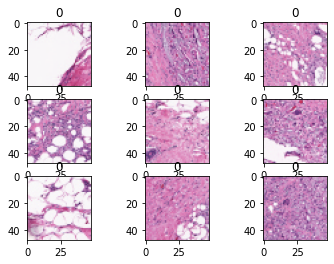

In [20]:
# configure batch size and retrieve one batch of images
for X_batch, y_batch in testGen:
    # create a grid of 3x3 images
    for i in range(0, 9):
        plt.subplot(330 + 1 + i)
        plt.imshow(X_batch[i], 
                   #cmap=pyplot.get_cmap('gray')
                  )
        plt.title(np.argmax(y_batch[i]))
    # show the plot   
    plt.show()
    break

In [23]:
# import the necessary packages
from tensorflow.keras import layers
import tensorflow_addons as tfa
from sklearn.metrics import accuracy_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import roc_auc_score, auc
from sklearn.metrics import roc_curve

## MHSA Transformer

In [24]:
class PatchExtract(layers.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        batch_size = tf.shape(images)[0]
        patches = tf.image.extract_patches(
            images=images,
            sizes=(1, self.patch_size, self.patch_size, 1),
            strides=(1, self.patch_size, self.patch_size, 1),
            rates=(1, 1, 1, 1),
            padding="VALID",
        )
        patch_dim = patches.shape[-1]
        patch_num = patches.shape[1]
        return tf.reshape(patches, (batch_size, patch_num * patch_num, patch_dim))


class PatchEmbedding(layers.Layer):
    def __init__(self, num_patch, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patch = num_patch
        self.proj = layers.Dense(embed_dim)
        self.pos_embed = layers.Embedding(input_dim=num_patch, output_dim=embed_dim)

    def call(self, patch):
        pos = tf.range(start=0, limit=self.num_patch, delta=1)
        return self.proj(patch) + self.pos_embed(pos)

In [25]:
def multihead_self_attention(
    x, dim, num_heads, attention_dropout=0, projection_dropout=0
):
    batch_size, num_patch, channels = tf.shape(x)[0], tf.shape(x)[1], tf.shape(x)[2]
    
    # Ensure that the dim is divisible by num_heads
    assert dim % num_heads == 0, "dim should be divisible by num_heads"
    
    # Linear layers for query, key, and value
    query = layers.Dense(dim)(x)
    key = layers.Dense(dim)(x)
    value = layers.Dense(dim)(x)
    
    # Reshape and transpose for multihead attention
    def reshape_and_transpose(tensor):
        return tf.transpose(tf.reshape(tensor, (batch_size, num_patch, num_heads, dim // num_heads)), perm=[0, 2, 1, 3])
    
    query = reshape_and_transpose(query)
    key = reshape_and_transpose(key)
    value = reshape_and_transpose(value)
    
    # Compute attention scores
    attention_scores = tf.matmul(query, key, transpose_b=True)
    attention_scores = attention_scores / tf.math.sqrt(tf.cast(dim // num_heads, tf.float32))
    
    # Apply softmax to get attention weights
    attention_weights = tf.nn.softmax(attention_scores, axis=-1)
    attention_weights = layers.Dropout(attention_dropout)(attention_weights)
    
    # Apply attention weights to values
    attention_output = tf.matmul(attention_weights, value)
    
    # Reshape and transpose back
    attention_output = tf.transpose(attention_output, perm=[0, 2, 1, 3])
    attention_output = tf.reshape(attention_output, (batch_size, num_patch, dim))
    
    # Final linear layer
    output = layers.Dense(dim)(attention_output)
    output = layers.Dropout(projection_dropout)(output)
    
    return output


In [26]:
def mlp(x, embedding_dim, mlp_dim, drop_rate=0.2):
    x = layers.Dense(mlp_dim, activation=tf.nn.gelu)(x)
    x = layers.Dropout(drop_rate)(x)
    x = layers.Dense(embedding_dim)(x)
    x = layers.Dropout(drop_rate)(x)
    return x

In [27]:
def transformer_encoder(
    x,
    embedding_dim,
    mlp_dim,
    num_heads,
    attention_dropout,
    projection_dropout,
    attention_type="mha_self_attention",
):
    residual_1 = x
    x = layers.LayerNormalization(epsilon=1e-5)(x)
    if attention_type == "mha_self_attention":
        x = multihead_self_attention(
            x,
            embedding_dim,
            num_heads,
            attention_dropout,
            projection_dropout,
        )
    elif attention_type == "mha_layer":
        x = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=embedding_dim, dropout=attention_dropout
        )(x, x)
    x = layers.add([x, residual_1])
    residual_2 = x
    x = layers.LayerNormalization(epsilon=1e-5)(x)
    x = mlp(x, embedding_dim, mlp_dim)
    x = layers.add([x, residual_2])
    return x

In [28]:
def get_model(attention_type="mha_self_attention"):
    inputs = layers.Input(shape=input_shape)
    # Image augment
    x = data_augmentation(inputs)
    # Extract patches.
    x = PatchExtract(patch_size)(x)
    # Create patch embedding.
    x = PatchEmbedding(num_patches, embedding_dim)(x)
    # Create Transformer block.
    for _ in range(num_transformer_blocks):
        x = transformer_encoder(
            x,
            embedding_dim,
            mlp_dim,
            num_heads,
            attention_dropout,
            projection_dropout,
            attention_type,
        )
    x = layers.GlobalAvgPool1D()(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

In [35]:
# data_augmentation = keras.Sequential(
#     [
#         layers.Normalization(),
#         layers.RandomFlip("horizontal"),
#         layers.RandomRotation(factor=0.1),
#         layers.RandomContrast(factor=0.1),
#         layers.RandomZoom(height_factor=0.2, width_factor=0.2),
#     ],
#     name="data_augmentation",
# )
# # Compute the mean and the variance of the training data for normalization.
# data_augmentation.layers[0].adapt(x_train)

IndexError: list index out of range

In [37]:
# Create and compile the model
model = get_model(attention_type="mha_self_attention")
model.compile(
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=label_smoothing),
    optimizer=tfa.optimizers.AdamW(
        learning_rate=learning_rate, weight_decay=weight_decay
    ),
    metrics=[
        keras.metrics.CategoricalAccuracy(name="accuracy"),
        keras.metrics.TopKCategoricalAccuracy(k=1, name="top_1_accuracy"),
        keras.metrics.AUC(name="auc", multi_label=True)
    ],
)

# # Assume x_train and y_train are your prepared dataset
# history = model.fit(
#     x_train,
#     y_train,
#     batch_size=batch_size,
#     epochs=num_epochs,
#     validation_split=validation_split,
# )

# # Save training history to JSON
# history_dict = history.history
# with open('training_history.json', 'w') as f:
#     json.dump(history_dict, f)

# print("Training history saved to training_history.json")

In [38]:
# # initialize our CancerNet model and compile it
# model = CancerNet_3.build(width=W, height=H, depth=C,classes=NUM_CLASSES)
# #opt = Adagrad(lr=INIT_LR, decay=INIT_LR / NUM_EPOCHS)
# model.compile(loss="binary_crossentropy",
#               optimizer='sgd',
#               metrics=["acc"])

model.summary()

Model: "model_1"
__________________________________________________________________________________________________
Layer (type)                    Output Shape         Param #     Connected to                     
input_3 (InputLayer)            [(None, 48, 48, 3)]  0                                            
__________________________________________________________________________________________________
data_augmentation (Sequential)  (None, 48, 48, 3)    7           input_3[0][0]                    
__________________________________________________________________________________________________
patch_extract_1 (PatchExtract)  (None, 9, 768)       0           data_augmentation[1][0]          
__________________________________________________________________________________________________
patch_embedding_1 (PatchEmbeddi (None, 9, 128)       99584       patch_extract_1[0][0]            
____________________________________________________________________________________________

In [39]:
totalValRos = valGen.n
totalValRos, classWeight, NUM_EPOCHS

(22201, array([1.       , 2.5202777], dtype=float32), 5)

In [40]:
totalTrain, totalTrain // BS + 1

(199818, 6245)

In [41]:
from keras.callbacks import ModelCheckpoint, LearningRateScheduler, EarlyStopping, ReduceLROnPlateau

FOLDS = 10

weight_path = 'mha_vit.hdf5'
print(weight_path)

checkpointer = ModelCheckpoint(weight_path,
                               monitor='loss',
                               verbose=1, 
                               save_best_only=True,
                               mode='min',
                               save_weights_only = True)


reduceLROnPlat = ReduceLROnPlateau(monitor='loss', 
                                   factor=0.8,
                                   patience=3, 
                                   verbose=1,
                                   mode='auto', 
                                   min_delta=0.0001,
                                   cooldown=3,
                                   min_lr=0.0001)

early_stopping = EarlyStopping(monitor="loss", mode="min", patience=3)


callbacks_list = [checkpointer, reduceLROnPlat, early_stopping]

Kaggle-FlexibleShape-48-CancerNet_3-sgd.hdf5


In [42]:
classWeight_array = {i : classWeight[i] for i in range(2)}
classWeight_array

{0: 1.0, 1: 2.5202777}

In [ ]:
import time, datetime
#from keras_tqdm import TQDMNotebookCallback
from tqdm import tqdm

#tqdm_callback = tfa.callbacks.TQDMProgressBar(show_epoch_progress=False)

model.reset_states()

t1 = time.time()
with tf.device('/device:GPU:0'):
    history_model = model.fit(trainGen,
                steps_per_epoch=totalTrain // BS + 1,
                validation_data=valGen,
                validation_steps=totalVal // BS + 1,
                class_weight=classWeight_array,
                epochs=NUM_EPOCHS, 
                verbose=1,
                callbacks=[
                    checkpointer,
                    reduceLROnPlat,
                    #early_stopping,
                    #tensorboard_callback
                    #TQDMNotebookCallback(leave_inner=False, leave_outer=True)
                ])
t2 = (time.time()-t1)/60
t3 = t2/60
print('Time used: {:2.2f} min'.format( t2 ))
print('Time used: {:2.2f} hrs'.format( t3 ))  

Epoch 1/5
1961/6245 [========>.....................] - ETA: 19:52 - loss: 0.8481 - accuracy: 0.7496 - top_1_accuracy: 0.7496 - auc: 0.8125

In [ ]:
def show_history(history_model):
    history = history_model
    acc = history.history['acc']
    val_acc = history.history['val_acc']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    #plt.figure(figsize=(10, 8), dpi=90)
    plt.figure()
    plt.title('Training and validation accuracy')
    plt.plot(epochs, acc, 'red', label='Training acc')
    plt.plot(epochs, val_acc, 'blue', label='Validation acc')
    plt.xlabel("Epochs", fontsize=14)
    plt.ylabel("Accuracy", fontsize=14)
    plt.legend()

    #plt.figure(figsize=(10, 8), dpi=90)
    plt.figure()
    plt.title('Training and validation loss')
    plt.plot(epochs, loss, 'red', label='Training loss')
    plt.plot(epochs, val_loss, 'blue', label='Validation loss')
    plt.xlabel("Epochs", fontsize=14)
    plt.ylabel("Loss", fontsize=14)

    plt.legend()

    plt.show()

In [ ]:
show_history(history_model)

# Evaluation Section

In [ ]:
model.load_weights(weight_path)
print("Loaded {} model from disk".format(weight_path))

In [ ]:
totalTest = testGen.n
totalTest

In [ ]:
y_test = testGen.classes
y_test.shape

In [ ]:
# reset the testing generator and then use our trained model to
# make predictions on the data
print("[INFO] evaluating network...")
testGen.reset()

t1 = time.time()
with tf.device('/device:GPU:0'):
    predIdxs = model.predict(testGen,
                            steps=(totalTest // BS)+1,
                                verbose=1)
t2 = (time.time()-t1)/60
print('Time used: {:2.2f} min'.format( t2 ))  

In [ ]:
print(predIdxs.shape)
predIdxs[:3]

In [ ]:
# for each image in the testing set we need to find the index of the
# label with corresponding largest predicted probability
#y_hat = np.argmax(predIdxs, axis=1)
y_hat = [np.argmax(y, axis=None, out=None) for y in predIdxs]
#target_names = testGen.class_indices.keys()
target_names = ['0', '1']
type(y_hat)

In [ ]:
totalTest, len(y_hat)

In [ ]:
y_true = y_test.copy()

In [ ]:
# show a nicely formatted classification report
print(classification_report(y_true, y_hat, target_names=target_names))

In [ ]:
from sklearn.metrics import balanced_accuracy_score

print('balanced acc:', balanced_accuracy_score(y_true, y_hat))

In [ ]:
from sklearn import metrics

print('f1_score weighted {:.4}'.format(metrics.f1_score(y_true, y_hat,
                                            average='weighted',
                                            labels=np.unique(y_hat))))
print('f1-score micro {:.4}'.format(metrics.f1_score(y_true, y_hat,
                                             average='micro', 
                                             labels=np.unique(y_hat))))
print('f1-score macro {:.4}'.format(metrics.f1_score(y_true, y_hat,
                                             average='macro',
                                             labels=np.unique(y_hat))))
print('ACC {:.4}'.format(metrics.accuracy_score(y_true, y_hat)))
print('Cohen_Kappa {:.4}'.format(metrics.cohen_kappa_score(y_true, y_hat)))

In [ ]:
#labelList = testGen.class_indices.keys()
labelList = target_names
cf = classification_report(y_pred=y_hat,
                            y_true=y_true,
                            target_names=labelList,
                            output_dict = True
                          )
print(type(cf))
print(cf.keys())

# https://www.mathsisfun.com/data/standard-deviation-formulas.html
# Standard Deviation of F1-score
mean_f1score = cf['weighted avg']['f1-score']
sum_msd = 0
for key, value in cf.items():
    if key in labelList:
        #print(type(value), value)
        mean_square_dif = (value['f1-score'] - mean_f1score)**2
        sum_msd += mean_square_dif
        print(key, 'f1-score: {:2.4f}'.format(value['f1-score']),
              'mean_square_dif: {:2.5f}'.format(mean_square_dif )
             )
        
std_f1score = (sum_msd*(1/len(labelList)))**(1/2)
print('mean_f1score: {:2.4f}'.format(mean_f1score), 
      'sd_f1score: {:2.4f}'.format(std_f1score))

In [ ]:
confusion_matrix(y_true, y_hat)

In [ ]:
# compute the confusion matrix and and use it to derive the raw
# accuracy, sensitivity, and specificity
cm = confusion_matrix(y_true, y_hat)
total = sum(sum(cm))
acc = (cm[0, 0] + cm[1, 1]) / total
sensitivity = cm[0, 0] / (cm[0, 0] + cm[0, 1])
specificity = cm[1, 1] / (cm[1, 0] + cm[1, 1])
bal_acc = (sensitivity+specificity)/2.0

In [ ]:
# show the confusion matrix, accuracy, sensitivity, and specificity
print(cm)
print("acc: {:.4f}".format(acc))
print("sensitivity: {:.4f}".format(sensitivity))
print("specificity: {:.4f}".format(specificity))

print("Balance acc: {:.4f}".format( bal_acc ))

In [ ]:
import seaborn as sns
#target_names = labelList

plt.figure(figsize=(3, 2), dpi=300)
accuracy = np.trace(cm) / float(np.sum(cm))
misclass = 1 - accuracy
tick_marks = np.arange(len(target_names))
plt.xticks(tick_marks, target_names, rotation=45, fontsize=8)
plt.yticks(tick_marks, target_names, fontsize=8)

#sns.set(font_scale=1.4)
cmap = sns.cubehelix_palette(dark=0, light=1, as_cmap=True)
ax = sns.heatmap(cm, annot=True,
                 cbar=True,
                 fmt='d', 
                 linewidths=.05,
                 xticklabels=target_names,
                 yticklabels=target_names,
                 cmap=cmap
                )

plt.tight_layout()
plt.ylabel('True label', fontsize=10)
plt.xlabel("Predicted label\naccuracy={:0.4f}\n misclass={:0.4f}".format(accuracy, misclass),
          fontsize=10)

In [ ]:
#cancernet
import seaborn as sns
#target_names = labelList

plt.figure(figsize=(3, 2), dpi=300)
accuracy = np.trace(cm) / float(np.sum(cm))
misclass = 1 - accuracy
tick_marks = np.arange(len(target_names))
plt.xticks(tick_marks, target_names, rotation=45, fontsize=8)
plt.yticks(tick_marks, target_names, fontsize=8)

#sns.set(font_scale=1.4)
cmap = sns.cubehelix_palette(dark=0, light=1, as_cmap=True)
cm_nor = cm.astype('float32') / cm.sum(axis=1)[:, np.newaxis]
ax = sns.heatmap(cm_nor, annot=True,
                 cbar=True,
                 fmt='.2f', 
                 linewidths=.05,
                 xticklabels=target_names,
                 yticklabels=target_names,
                 cmap=cmap
                )

plt.tight_layout()
plt.ylabel('True label', fontsize=10)
plt.xlabel("Predicted label\naccuracy={:0.4f}\n misclass={:0.4f}".format(accuracy, misclass),
          fontsize=10)

In [ ]:
y_testHot = np_utils.to_categorical(y_test)
y_testHot.shape

In [ ]:
import numpy as np 
from scipy import interp 
import matplotlib.pyplot as plt 
from itertools import cycle 
from sklearn.metrics import roc_curve, auc
from matplotlib.pyplot import figure
y_score = predIdxs.copy()
y_test = y_testHot.copy()

y_score.shape, y_test.shape

In [ ]:
# Plot linewidth.
lw = 2
n_classes = NUM_CLASSES

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    
# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Compute macro-average ROC curve and ROC area

# First aggregate all false positive rates
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))

# Then interpolate all ROC curves at this points
mean_tpr = np.zeros_like(all_fpr)
for i in range(n_classes):
    mean_tpr += interp(all_fpr, fpr[i], tpr[i])

# Finally average it and compute AUC
mean_tpr /= n_classes

fpr["macro"] = all_fpr
tpr["macro"] = mean_tpr
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot all ROC curves
#plt.figure
plt.figure(num=None, figsize=(8, 6), dpi=300, facecolor='w', edgecolor='k')
plt.plot(fpr["micro"], tpr["micro"],
         label='micro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc["micro"]),
         color='deeppink', linestyle=':', linewidth=4)

plt.plot(fpr["macro"], tpr["macro"],
         label='macro-average ROC curve (area = {0:0.2f})'
               ''.format(roc_auc["macro"]),
         color='navy', linestyle=':', linewidth=4)

#colors = cycle(['aqua', 'darkorange', 'cornflowerblue',
#               'red', 'darkgoldenrod', 'darkgreen',
#               'darkmagenta', 'navy', 'firebrick', 'rosybrown'])

colors = cycle(['#e6194B', '#3cb44b']) #red and green

for i, color in zip(range(n_classes), colors):
            plt.plot(fpr[i], tpr[i], color=color, lw=lw,
                     label='ROC curve of class {}: {} (area = {:.2f})'
                     ''.format(i, labelList[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=lw)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('1 - Specificity', fontsize=14)
plt.ylabel('Sensitivity', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
#plt.title('Receiver operating characteristic to multi-class', fontsize=16)
#plt.legend(loc="lower right")
plt.legend(#lines, labels, 
            #loc=(0, -0.6),
            #loc='best'
            #prop=dict(size=12), 
            loc="lower right"
            )
plt.show()

In [ ]:
FP = cm.sum(axis=0) - np.diag(cm)  
FN = cm.sum(axis=1) - np.diag(cm)
TP = np.diag(cm)
#TN = cm.values.sum() - (FP + FN + TP)
TN = cm.sum() - (FP + FN + TP)


# Sensitivity, hit rate, recall, or true positive rate
TPR = TP/(TP+FN)
# Specificity or true negative rate
TNR = TN/(TN+FP) 
# Precision or positive predictive value
PPV = TP/(TP+FP)
# Negative predictive value
NPV = TN/(TN+FN)
# Fall out or false positive rate
FPR = FP/(FP+TN)
# False negative rate
FNR = FN/(TP+FN)
# False discovery rate
FDR = FP/(TP+FP)

# Overall accuracy
ACC = (TP+TN)/(TP+FP+FN+TN)

p_measures = dict()
p_measures = {
    'TP': TP,
    'TN': TN,
    'FP': FP,
    'FN': FN,
    'TPR': TPR,
    'TNR': TNR,
    'PPV': PPV,
    'NPV': NPV,
    'FPR': FPR,
    'FNR': FNR,
    'FDR': FDR,
    'ACC': ACC
}
for key, value in p_measures.items():
    print(key, value, '\nMean: {:.4f}'.format(value.mean()), 
          '\tSD: {:.4f}'.format(value.std()), '\n')


In [ ]:
# Plot precision_recall_curve
test_labels = y_hat
precision = dict()
recall = dict()
average_precision = dict()
n_classes = NUM_CLASSES
y_score.shape, y_test.shape

In [ ]:
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score

    #Y_test = test_labels #in one hot array
    #n_classes = 10
    #y_score from model.predict

    # For each class
    #precision = dict()
    #recall = dict()
    #average_precision = dict()
    
def plot_precision_recall_curve(y_score, Y_test, n_classes):   
    for i in range(n_classes):
        precision[i], recall[i], _ = precision_recall_curve(Y_test[:, i],
                                                            y_score[:, i])
        average_precision[i] = average_precision_score(Y_test[:, i], y_score[:, i])

    # A "micro-average": quantifying score on all classes jointly
    precision["micro"], recall["micro"], _ = precision_recall_curve(Y_test.ravel(),
        y_score.ravel())
    average_precision["micro"] = average_precision_score(Y_test, y_score,
                                                         average="micro")
    print('Average precision score, micro-averaged over all classes: {0:0.2f}'
          .format(average_precision["micro"]))

    #plt.figure()
    plt.figure(num=None, figsize=(8, 6), dpi=300, facecolor='w', edgecolor='k')
    plt.step(recall['micro'], precision['micro'], color='b', alpha=0.2,
             where='post')
    plt.fill_between(recall["micro"], precision["micro"], alpha=0.2, color='g',
                     #**step_kwargs
                    )
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)

    plt.xlabel('Sensitivity', fontsize=14)
    plt.ylabel('Precision', fontsize=14)
    plt.ylim([0.0, 1.05])
    plt.xlim([0.0, 1.0])
    plt.title(
        'Average precision score, micro-averaged over all classes: AP={0:0.2f}'
        .format(average_precision["micro"]), fontsize=14)
    
plot_precision_recall_curve(y_score=y_score, Y_test=y_test, n_classes=NUM_CLASSES)

In [ ]:
def plot_precision_recall_each_class():
    from itertools import cycle
    # setup plot details
#     colors = cycle(['aqua', 'darkorange', 'cornflowerblue',
#                'red', 'darkgoldenrod', 'darkgreen',
#                'darkmagenta', 'navy', 'firebrick', 'rosybrown'])
    colors = cycle(['deeppink', 'navy'])

    #plt.figure(figsize=(7, 8))
    plt.figure(num=None, figsize=(8, 6), dpi=300, facecolor='w', edgecolor='k')

    f_scores = np.linspace(0.2, 0.8, num=4)
    lines = []
    labels = []
    for f_score in f_scores:
        x = np.linspace(0.01, 1)
        y = f_score * x / (2 * x - f_score)
        l, = plt.plot(x[y >= 0], y[y >= 0], color='gray', alpha=0.2)
        plt.annotate('f1={0:0.1f}'.format(f_score), xy=(0.9, y[45] + 0.02))

    lines.append(l)
    labels.append('iso-f1 curves')
    l, = plt.plot(recall["micro"], precision["micro"], color='gold', lw=2)
    lines.append(l)
    labels.append('micro-average Precision-Sensitivity (area = {0:0.2f})'
                  ''.format(average_precision["micro"]))

    for i, color in zip(range(n_classes), colors):
        l, = plt.plot(recall[i], precision[i], color=color, lw=2)
        lines.append(l)
        labels.append('Precision-Sensitivity for class {}: {} (area = {:.2f})'
                     ''.format(i, labelList[i], average_precision[i]))

    #plt.figure(num=None, figsize=(8, 6), dpi=300, facecolor='w', edgecolor='k')

    fig = plt.gcf()
    fig.subplots_adjust(bottom=0.25)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.xlabel('Sensitivity', fontsize=14)
    plt.ylabel('Precision', fontsize=14)
    #plt.title('Extension of Precision-Recall curve to multi-class', fontsize=16)
    
    plt.legend(lines, labels, 
               #loc=(0, -.75), 
               #prop=dict(size=14), 
               loc="lower left"
              )
    plt.show()
    
plot_precision_recall_each_class() 